# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import base64
from csv_runs import notebook_csv_path


In [2]:
import ratinabox
from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from ratinabox.Neurons import FieldOfViewOVCs
# from ratinabox.Neurons import PlaceCells, GridCells #...

## aux funcs

In [3]:
import random
import string

def generate_random_string(n):
    """
    Generate a random string of length n.

    Parameters:
    n (int): The desired length of the string.

    Returns:
    str: A random string of length n.
    """
    if n <= 0:
        raise ValueError("Length 'n' must be a positive integer.")

    # Combine letters, digits, and punctuation
    characters = string.ascii_uppercase
    
    # Generate a random string of length n
    random_string = ''.join(random.choices(characters, k=n))

    return random_string


In [4]:
generate_random_string(8)

'XLSODTPH'

In [5]:
def get_rand_letter(x):
    if x <= 0.2:
        return 'A'
    elif x > 0.2 and x <= 0.4:
        return 'B'
    elif x > 0.4 and x <= 0.6:
        return 'C'
    elif x > 0.6 and x <= 0.8:
        return 'D'
    else:
        return 'E'

In [6]:
def is_point_in_hole(point, hole):
    """
    Verifica se um ponto está dentro de um polígono (hole).
    """
    x, y = point
    n = len(hole)
    inside = False

    px, py = hole[0]
    for i in range(1, n + 1):
        cx, cy = hole[i % n]
        if y > min(py, cy):
            if y <= max(py, cy):
                if x <= max(px, cx):
                    if py != cy:
                        xinters = (y - py) * (cx - px) / (cy - py) + px
                        if px == cx or x <= xinters:
                            inside = not inside
        px, py = cx, cy

    return inside

In [7]:
def is_point_valid(point, hole=None):
    if hole is not None:
        x_valid = True
        y_valid = True
        point_valid = True
        hole_x_inf = hole[0][0]
        hole_x_sup = hole[1][0]
        hole_y_inf = hole[0][1]
        hole_y_sup = hole[1][1]
        # check x pos
        if (point[0] > hole_x_inf) and (point[0] < hole_x_sup):
            x_valid = False
        if (point[1] > hole_y_inf) and (point[1] < hole_y_sup):
            y_valid = False
        if (not x_valid or  not y_valid) or (not x_valid and y_valid):
            point_valid = False
        # print(point, point_valid, x_valid, y_valid)
        return point_valid
    else:
        return True

In [8]:
def generate_all_positions_on_env(hole=None):

        # Define the range and step size
    step = 0.01  # Adjust the step size for granularity
    x_range = np.arange(0, 1 + step, step)
    y_range = np.arange(0, 1 + step, step)

    # Create a grid of (x, y) positions
    x, y = np.meshgrid(x_range, y_range)
    positions = np.column_stack([x.ravel(), y.ravel()])

    # Convert to a pandas DataFrame
    df_positions = pd.DataFrame(positions, columns=["X", "Y"])
    df_positions['is_valid'] = [int(is_point_valid(pos, hole)) for pos in positions]
    df_positions['pos'] = [val for val in positions]

    return df_positions

In [9]:
def get_euclidean_distance(pos1, pos2):
    return np.sqrt((pos1[0] - pos2[0])**2 + ((pos1[1] - pos2[1])**2))
def apply_eucd_dist(x, obj=9):
    return get_euclidean_distance(x['pos'], x[f'obj_{obj}_pos'])

In [10]:
np.random.rand(3, 1)

array([[0.27236117],
       [0.28738147],
       [0.12710597]])

In [11]:
hole_deff = [[0.4,0.2],[0.6,0.2],[0.6,0.8],[0.4,0.8]]

In [12]:
generate_all_positions_on_env(hole_deff)['is_valid'].mean()

0.8118811881188119

In [13]:
hole_deff[1][0]

0.6

## Define EnV

In [14]:
Env = Environment(params={
    'aspect':1,
    # 'holes' : [[[0.4,0.2],[0.6,0.2],[0.6,0.8],[0.4,0.8]]],
    })

### Num of Cues

In [15]:
Env.has_holes

False

In [16]:
NUM_OF_CUES = 100

### RUN PARAMETERS

In [17]:
CUE_NAME_LEN = 4

MAX_NUMBER_OF_CUES = 5
CONTEXT_LEN = MAX_NUMBER_OF_CUES*CUE_NAME_LEN
CONTEXT_LEN

20

### gerando cues positions

In [18]:
CUES_LIST = []
num_test = 0
for i in range(NUM_OF_CUES):
    if Env.has_holes:
        candidate_point = 0.45, 0.55
        while not is_point_valid(candidate_point, hole_deff):
            candidate_point = np.random.rand(), np.random.rand()
            num_test+=1
        CUES_LIST.append(candidate_point)
    else:
        candidate_point = np.random.rand(), np.random.rand()
        CUES_LIST.append(candidate_point)
print(f'{NUM_OF_CUES} cues criadas com {num_test} candidatos')

100 cues criadas com 0 candidatos


### gerando all positions df

In [19]:
ap = generate_all_positions_on_env(hole=None)
ap.head()

,X,Y,is_valid,pos
0,0.00,0.0,1,"[0.0, 0.0]"
1,0.01,0.0,1,"[0.01, 0.0]"
2,0.02,0.0,1,"[0.02, 0.0]"
3,0.03,0.0,1,"[0.03, 0.0]"
4,0.04,0.0,1,"[0.04, 0.0]"


### adicionando cues ao EnV

In [20]:
for point in CUES_LIST:
    Env.add_object(object=point,type=0)

In [21]:
len(Env.objects['objects']), NUM_OF_CUES

(100, 100)

In [22]:
objects_name_list = []
for i in range(NUM_OF_CUES):
    obj_name = generate_random_string(CUE_NAME_LEN)
    if obj_name in objects_name_list:
        obj_name = generate_random_string(CUE_NAME_LEN)
    objects_name_list.append(obj_name)

In [23]:
len(objects_name_list), len(set(objects_name_list))

(100, 100)

In [32]:
# # objetos a direita do buraco
# Env.add_object(object=[0.9,0.3],type=0)
# Env.add_object(object=[0.7,0.1],type=0)
# Env.add_object(object=[0.7,0.5],type=0)
# Env.add_object(object=[0.9,0.7],type=0)
# Env.add_object(object=[0.7,0.9],type=0)


# # objetos a esquerda do buraco
# Env.add_object(object=[0.3,0.3],type=0)
# Env.add_object(object=[0.1,0.1],type=0)
# Env.add_object(object=[0.1,0.5],type=0)
# Env.add_object(object=[0.3,0.7],type=0)
# Env.add_object(object=[0.1,0.9],type=0)

In [24]:
objects_name_list[:3]

['CRTK', 'GUMW', 'ORLH']

In [25]:
Env.objects['object_names'] = objects_name_list

In [26]:
# Env.objects

### add encode to obj

In [27]:
OBJ_ENCODE_DIM = 3

In [28]:
np.matmul(np.random.rand(1, 3), np.random.rand(3, 1))

array([[1.20589867]])

In [29]:
objects_encode_list = []
for i in range(NUM_OF_CUES):
    obj_enc = np.random.rand(3, 1)
    # if obj_enc in objects_encode_list:
        # obj_enc = np.random.rand(3, 1)
    objects_encode_list.append(obj_enc)

In [30]:
Env.objects['object_encs'] = objects_encode_list

## vizz env

    • To AUTOMATICALLY save all plots (recommended), set  `ratinabox.autosave_plots = True`
    • To MANUALLY save plots, call                        `ratinabox.utils.save_figure(figure_object, save_title).
      This warning will not be shown again
HINT: You can stylize plots to make them look like repo/paper by calling `ratinabox.stylize_plots()`
      This hint will not be shown again


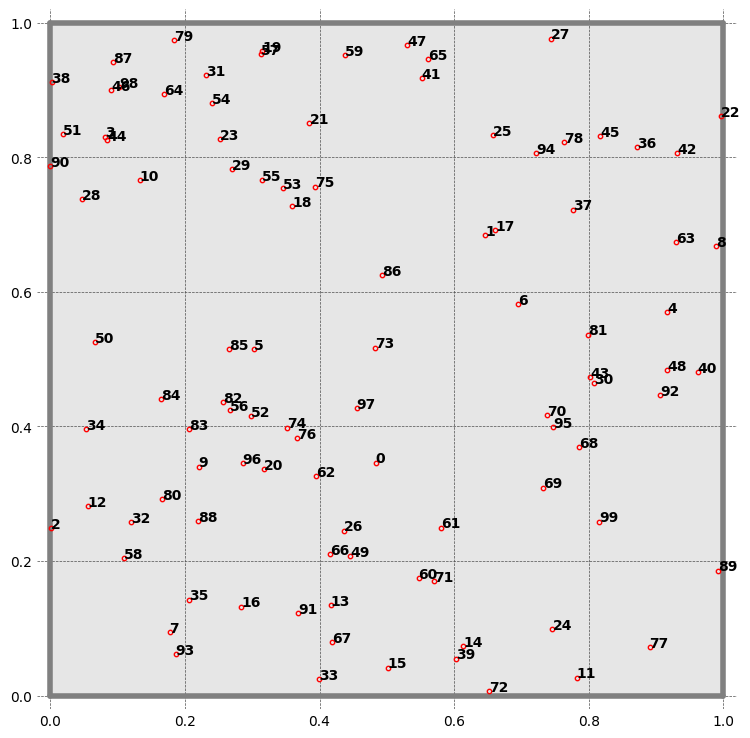

In [31]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax) #visualises current environment with walls and objects
# Agent.plot_trajectory() #plots trajectory
# Agent.animate_trajectory() #animate trajectory
# Neurons.plot_rate_map() # plots the rate map of the neurons at all positions
# Neurons.plot_rate_timeseries() # plots activities of the neurons over time 
# Neurons.animate_rate_timeseries() # animates the activity of the neurons over time 
plt.show()

In [32]:
Ag = Agent(Env)

# agent configs
# Ag.pos = start_pos
Ag.thigmotaxis = 0.2

In [204]:
# default_params = {
#         "distance_range": [0.02, 0.4],  # min and max distances the agent can "see"
#         "angle_range": [0,75],  # angluar FoV in degrees (will be symmetric on both sides, so give range in 0 (forwards) to 180 (backwards)
#         "spatial_resolution": 0.02,  # resolution of each BVC tiling FoV
#         "beta": 5, # smaller means larger rate of increase of cell size with radius in hartley type manifolds
#         "cell_arrangement": "diverging_manifold",  # whether all cells have "uniform" receptive field sizes or they grow ("hartley") with radius.
#         "object_tuning_type" : None, #can be "random", any integer, or a list of integers of length n. The tuning types of the OVCs.
#     }

In [205]:
# new_params = {
#         "distance_range": [0.001, 1],  # min and max distances the agent can "see"
#         "angle_range": [0,180],  # angluar FoV in degrees (will be symmetric on both sides, so give range in 0 (forwards) to 180 (backwards)
#         "spatial_resolution": 0.02,  # resolution of each BVC tiling FoV
#         "beta": 5, # smaller means larger rate of increase of cell size with radius in hartley type manifolds
#         "cell_arrangement": "diverging_manifold",  # whether all cells have "uniform" receptive field sizes or they grow ("hartley") with radius.
#         "object_tuning_type" : 0, #can be "random", any integer, or a list of integers of length n. The tuning types of the OVCs.
#     }

In [206]:
# FoV_OVCs = FieldOfViewOVCs(Ag,new_params)

In [33]:
MINUTES = 60

In [34]:
for i in range(int(MINUTES*60/Ag.dt)):
    Ag.update()
    # FoV_OVCs.update()

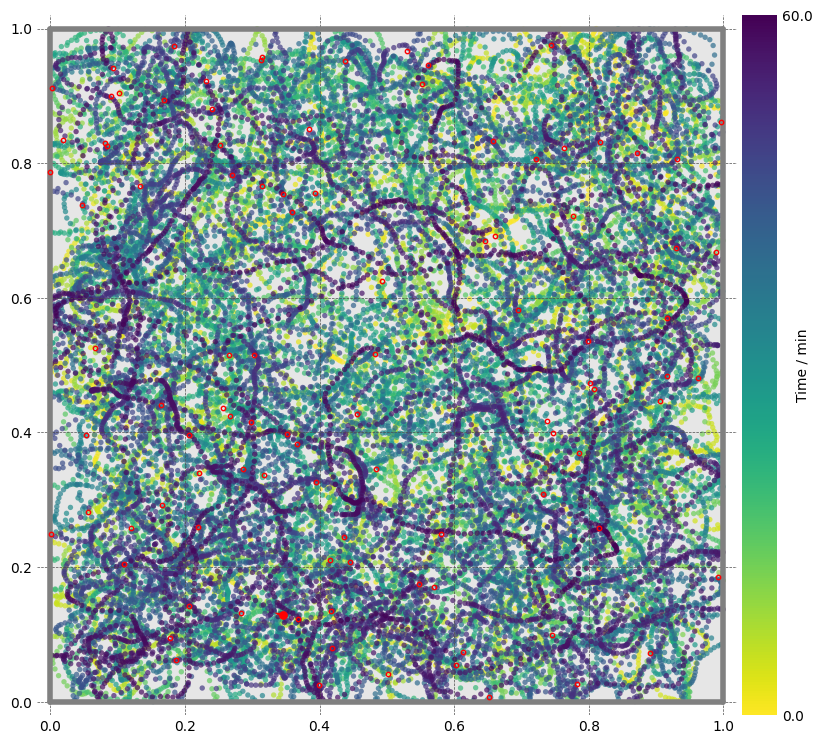

In [35]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax)
plt.show()

# init dfbase

In [36]:
dfbase = pd.DataFrame(Ag.history).copy()
print(dfbase.shape)
dfbase.head(2)

(72000, 6)


,t,pos,distance_travelled,vel,rot_vel,head_direction
0,0.05,"[0.7234225096319985, 0.6590180721447932]",0.002518,"[0.050026833406831006, -0.005830988477233401]",2.538174,"[0.9799342121008388, -0.19932119795523082]"
1,0.10,"[0.7260568800059078, 0.6588409872251387]",0.005159,"[0.0526874074781869, -0.0035416983930902646]",0.978253,"[0.9878287433044572, -0.15554540784457951]"


In [37]:
# df = dfbase.iloc[:150].copy() #dfbase[dfbase.index%10 == 0].copy()
df = dfbase.copy()
df.shape

(72000, 6)

In [212]:
# Env.objects

In [213]:
# fixed_object = 8
# Env.objects['objects'][fixed_object]

In [214]:
# Env.objects

## adding obj pos and names to dfbase

In [38]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in df.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in df.index],
         f'obj_{i}_enc':[Env.objects['object_encs'][i] for _ in df.index]}
    cue_df = pd.DataFrame(data=cue_dict, index=df.index)  
    df = pd.concat([df, cue_df], axis=1)
    # df[f'obj_{i}_pos'] = [Env.objects['objects'][i] for _ in df.index]
    # df[f'obj_{i}_name'] = [Env.objects['object_names'][i] for _ in df.index]

In [39]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in ap.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in ap.index]}
    cue_ap = pd.DataFrame(data=cue_dict, index=ap.index)  
    ap = pd.concat([ap, cue_ap], axis=1)
    # df[f'obj_{i}_pos'] = [Env.objects['objects'][i] for _ in df.index]
    # df[f'obj_{i}_name'] = [Env.objects['object_names'][i] for _ in df.index]

In [40]:
ap.head()

,X,Y,is_valid,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,...,obj_95_pos,obj_95_name,obj_96_pos,obj_96_name,obj_97_pos,obj_97_name,obj_98_pos,obj_98_name,obj_99_pos,obj_99_name
0,0.00,0.0,1,"[0.0, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,"[0.7472939062973158, 0.3996392083118312]",TMBP,"[0.285711951192124, 0.34503033107828074]",XBAC,"[0.4550786008954787, 0.42681218141820476]",XDTT,"[0.10239235077394715, 0.9039841590939425]",IEHS,"[0.8158999474429386, 0.25872196917734314]",BWKU
1,0.01,0.0,1,"[0.01, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,"[0.7472939062973158, 0.3996392083118312]",TMBP,"[0.285711951192124, 0.34503033107828074]",XBAC,"[0.4550786008954787, 0.42681218141820476]",XDTT,"[0.10239235077394715, 0.9039841590939425]",IEHS,"[0.8158999474429386, 0.25872196917734314]",BWKU
2,0.02,0.0,1,"[0.02, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,"[0.7472939062973158, 0.3996392083118312]",TMBP,"[0.285711951192124, 0.34503033107828074]",XBAC,"[0.4550786008954787, 0.42681218141820476]",XDTT,"[0.10239235077394715, 0.9039841590939425]",IEHS,"[0.8158999474429386, 0.25872196917734314]",BWKU
3,0.03,0.0,1,"[0.03, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,"[0.7472939062973158, 0.3996392083118312]",TMBP,"[0.285711951192124, 0.34503033107828074]",XBAC,"[0.4550786008954787, 0.42681218141820476]",XDTT,"[0.10239235077394715, 0.9039841590939425]",IEHS,"[0.8158999474429386, 0.25872196917734314]",BWKU
4,0.04,0.0,1,"[0.04, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,"[0.7472939062973158, 0.3996392083118312]",TMBP,"[0.285711951192124, 0.34503033107828074]",XBAC,"[0.4550786008954787, 0.42681218141820476]",XDTT,"[0.10239235077394715, 0.9039841590939425]",IEHS,"[0.8158999474429386, 0.25872196917734314]",BWKU


In [41]:
df.shape

(72000, 306)

In [42]:
df.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_0_enc,obj_1_pos,...,obj_96_enc,obj_97_pos,obj_97_name,obj_97_enc,obj_98_pos,obj_98_name,obj_98_enc,obj_99_pos,obj_99_name,obj_99_enc
0,0.05,"[0.7234225096319985, 0.6590180721447932]",0.002518,"[0.050026833406831006, -0.005830988477233401]",2.538174,"[0.9799342121008388, -0.19932119795523082]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[[0.011352084615431912], [0.8106353509772771],...","[0.6465135712032417, 0.6843316975396493]",...,"[[0.7817556867365513], [0.13690330009049934], ...","[0.4550786008954787, 0.42681218141820476]",XDTT,"[[0.32519907202860754], [0.40449214639985187],...","[0.10239235077394715, 0.9039841590939425]",IEHS,"[[0.5321473772799917], [0.13596879392968042], ...","[0.8158999474429386, 0.25872196917734314]",BWKU,"[[0.3173141103908127], [0.7514070951659363], [..."
1,0.10,"[0.7260568800059078, 0.6588409872251387]",0.005159,"[0.0526874074781869, -0.0035416983930902646]",0.978253,"[0.9878287433044572, -0.15554540784457951]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[[0.011352084615431912], [0.8106353509772771],...","[0.6465135712032417, 0.6843316975396493]",...,"[[0.7817556867365513], [0.13690330009049934], ...","[0.4550786008954787, 0.42681218141820476]",XDTT,"[[0.32519907202860754], [0.40449214639985187],...","[0.10239235077394715, 0.9039841590939425]",IEHS,"[[0.5321473772799917], [0.13596879392968042], ...","[0.8158999474429386, 0.25872196917734314]",BWKU,"[[0.3173141103908127], [0.7514070951659363], [..."


## measure distances to objs

In [43]:
for i in range(NUM_OF_CUES):
    dist_cue_dict = {f'dist_to_obj_{i}': df.apply(apply_eucd_dist, axis=1, obj=i)}
    dist_cue_df = pd.DataFrame(data=dist_cue_dict, index=df.index)
    df = pd.concat([df, dist_cue_df], axis=1)

In [44]:
for i in range(NUM_OF_CUES):
    dist_cue_dict = {f'dist_to_obj_{i}': ap.apply(apply_eucd_dist, axis=1, obj=i)}
    dist_cue_ap = pd.DataFrame(data=dist_cue_dict, index=ap.index)
    ap = pd.concat([ap, dist_cue_ap], axis=1)

In [46]:
ap.head()

,X,Y,is_valid,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,...,dist_to_obj_90,dist_to_obj_91,dist_to_obj_92,dist_to_obj_93,dist_to_obj_94,dist_to_obj_95,dist_to_obj_96,dist_to_obj_97,dist_to_obj_98,dist_to_obj_99
0,0.00,0.0,1,"[0.0, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.786666,0.388085,1.010360,0.195937,1.082175,0.847443,0.447970,0.623911,0.909765,0.855938
1,0.01,0.0,1,"[0.01, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.786729,0.378615,1.001401,0.186471,1.075529,0.838638,0.441659,0.616655,0.908693,0.846411
2,0.02,0.0,1,"[0.02, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.786918,0.369172,0.992462,0.177065,1.068936,0.829860,0.435487,0.609477,0.907731,0.836895
3,0.03,0.0,1,"[0.03, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.787235,0.359760,0.983544,0.167727,1.062395,0.821110,0.429458,0.602379,0.906878,0.827391
4,0.04,0.0,1,"[0.04, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.787679,0.350380,0.974646,0.158470,1.055909,0.812389,0.423580,0.595364,0.906135,0.817898


In [45]:
f"{100*len(df)} iteracoes"

'7200000 iteracoes'

In [222]:
df.shape

(72000, 66)

In [223]:
df.tail(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_0_enc,obj_1_pos,...,dist_to_obj_5,dist_to_obj_6,dist_to_obj_7,dist_to_obj_8,dist_to_obj_9,dist_to_obj_10,dist_to_obj_11,dist_to_obj_12,dist_to_obj_13,dist_to_obj_14
71998,3599.95,"[0.7331307443778559, 0.536011724352319]",351.079365,"[-0.07689004472861471, 0.0469055815125885]",2.448999,"[-0.8551613851116473, 0.5183618479536556]","[0.38798593827367855, 0.9805671096022476]",RUIZ,"[[0.15184775543595386], [0.7833317405988385], ...","[0.26280893128411154, 0.1910002672169574]",...,0.493854,0.196727,0.574201,0.317124,0.585638,0.315885,0.368213,0.414697,0.726174,0.338980
71999,3600.00,"[0.7295311411257703, 0.5373933637453234]",351.083221,"[-0.07199206504171052, 0.027632787860087937]",3.625519,"[-0.8844308711810898, 0.466671226991614]","[0.38798593827367855, 0.9805671096022476]",RUIZ,"[[0.15184775543595386], [0.7833317405988385], ...","[0.26280893128411154, 0.1910002672169574]",...,0.495172,0.200389,0.570804,0.314946,0.581796,0.315305,0.370303,0.412815,0.724243,0.337489


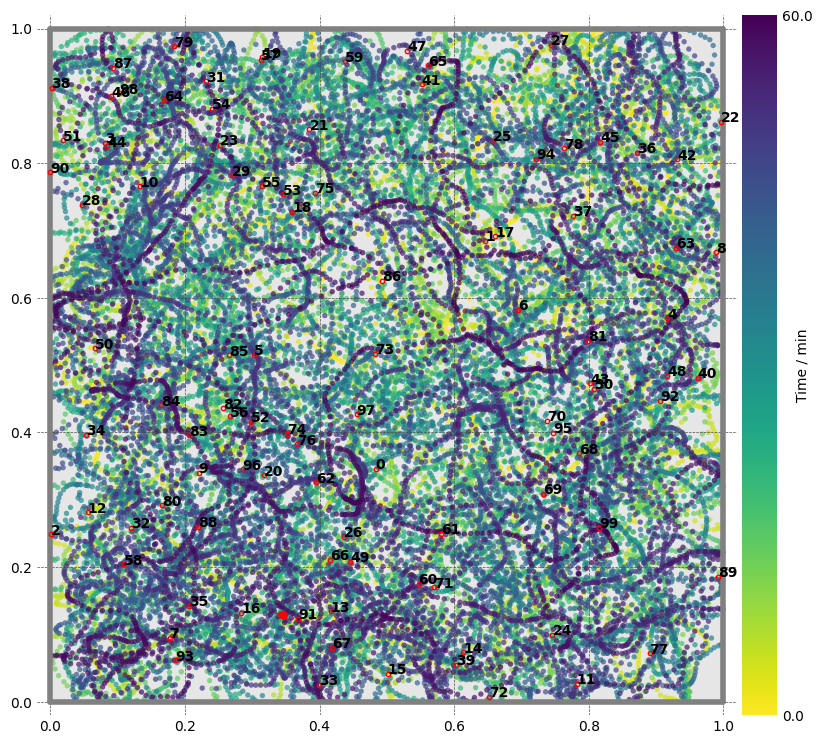

In [47]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=df['t'].max())

plt.show()

In [48]:
obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]

# def get_position_text(x):

In [49]:
np.hstack(objects_encode_list[0:3]).reshape(1, 3, 3)

array([[[0.01135208, 0.40454501, 0.9120514 ],
        [0.81063535, 0.74184501, 0.45741424],
        [0.98258304, 0.67506115, 0.13547652]]])

## create positions

In [50]:
def apply_cps_to_positions(df, obj_dist_cols):
    dft = df[obj_dist_cols].T
    dft.columns = [f't_{i:08d}' for i in range(df.T.shape[1])]
    order = [int(val.split('_')[-1]) for val in dft.sort_values(dft.columns[0]).index[:MAX_NUMBER_OF_CUES]]
    # dft.sort_values(dft.columns[0])

    positions_list = []
    position_enc_list = []
    for feat in dft.columns:
        order = [int(val.split('_')[-1]) for val in dft.sort_values(feat).index[:MAX_NUMBER_OF_CUES]]
        positions_list.append(''.join([obj_names[i] for i in order]))
        position_enc_list.append(np.hstack([objects_encode_list[i] for i in order]))

    # len(positions_list)


    pos_state_dict = {'position_state':[val for val in positions_list],
                        'encode_position_state':[val for val in position_enc_list]}
    pos_state_df = pd.DataFrame(data=pos_state_dict, index=df.index)
    return pd.concat([df, pos_state_df], axis=1).copy()

In [228]:
# df_ = apply_cps_to_positions(df, obj_dist_cols)
# df_.shape

(72000, 68)

In [229]:
# dft = df[obj_dist_cols].T
# dft.columns = [f't_{i:08d}' for i in range(df.T.shape[1])]

In [230]:
# dft.columns[0]

In [231]:
# order = [int(val.split('_')[-1]) for val in dft.sort_values(dft.columns[0]).index[:MAX_NUMBER_OF_CUES]]
# dft.sort_values(dft.columns[0])

In [232]:
# order

In [233]:
# pos_text = ''.join([obj_names[i] for i in order])
# pos_text

In [234]:
# ap.head()

In [235]:
# Env.objects['object_names']

In [236]:
# positions_list = []
# for feat in dft.columns:
#     order = [int(val.split('_')[-1]) for val in dft.sort_values(feat).index[:MAX_NUMBER_OF_CUES]]
#     positions_list.append(''.join([obj_names[i] for i in order]))
# len(positions_list)

In [237]:
# pos_state_dict = {'position_state':[val for val in positions_list]}
# pos_state_df = pd.DataFrame(data=pos_state_dict, index=df.index)
# df = pd.concat([df, pos_state_df], axis=1)
# df.head(2)

In [51]:
dfp = apply_cps_to_positions(df, obj_dist_cols)
dfp.shape

(72000, 408)

In [52]:
apd = apply_cps_to_positions(ap, obj_dist_cols)
apd.shape

(10201, 306)

In [54]:
apd.shape

(10201, 306)

In [55]:
len(dfp), dfp['position_state'].nunique()/len(dfp), dfp['position_state'].nunique()

(72000, 0.067125, 4833)

In [56]:
len(apd), apd['position_state'].nunique()/len(apd), apd['position_state'].nunique()

(10201, 0.317419860797961, 3238)

In [57]:
apd.head()

,X,Y,is_valid,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,...,dist_to_obj_92,dist_to_obj_93,dist_to_obj_94,dist_to_obj_95,dist_to_obj_96,dist_to_obj_97,dist_to_obj_98,dist_to_obj_99,position_state,encode_position_state
0,0.00,0.0,1,"[0.0, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,1.010360,0.195937,1.082175,0.847443,0.447970,0.623911,0.909765,0.855938,WYHEUXUBQOSHORLHQJIQ,"[[0.34659185925924296, 0.6495233614663888, 0.4..."
1,0.01,0.0,1,"[0.01, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,1.001401,0.186471,1.075529,0.838638,0.441659,0.616655,0.908693,0.846411,WYHEUXUBQOSHQJIQORLH,"[[0.34659185925924296, 0.6495233614663888, 0.4..."
2,0.02,0.0,1,"[0.02, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.992462,0.177065,1.068936,0.829860,0.435487,0.609477,0.907731,0.836895,WYHEUXUBQOSHQJIQORLH,"[[0.34659185925924296, 0.6495233614663888, 0.4..."
3,0.03,0.0,1,"[0.03, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.983544,0.167727,1.062395,0.821110,0.429458,0.602379,0.906878,0.827391,WYHEUXUBQOSHQJIQORLH,"[[0.34659185925924296, 0.6495233614663888, 0.4..."
4,0.04,0.0,1,"[0.04, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.974646,0.158470,1.055909,0.812389,0.423580,0.595364,0.906135,0.817898,WYHEUXUBQOSHQJIQORLH,"[[0.34659185925924296, 0.6495233614663888, 0.4..."


In [58]:
num_unique_pos = dfp['position_state'].nunique()
num_unique_pos

4833

In [59]:
dfp['position_state_id'] = (dfp.groupby('position_state').transform('ngroup'))
dfp['normalized_position_state_id']  = (dfp['position_state_id'] / num_unique_pos)
dfp[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
11026,1758,0.363749
1068,1114,0.230499
1554,1967,0.406994
6711,3810,0.788330
34920,3966,0.820608


In [60]:
apd['position_state_id'] = (apd.groupby('position_state').transform('ngroup'))
apd['normalized_position_state_id']  = (apd['position_state_id'] / num_unique_pos)
apd[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
8635,1193,0.246845
4762,846,0.175047
4051,1125,0.232775
7735,968,0.200290
7060,174,0.036002


In [62]:
apd[['X', 'Y','position_state_id', 'position_state']].sample(5)

,X,Y,position_state_id,position_state
8161,0.81,0.80,2887,WFMVDDUZDICNRSZBXWOF
3361,0.28,0.33,3076,XBACRHMMKJOANJXJWJEC
7932,0.54,0.78,326,CKBQHUXKGUMWRWBYSLLN
9952,0.54,0.98,1469,JQUVXVAVHUXKDVAICKBQ
4228,0.87,0.41,1077,HOCCMOFUFXYRHFTJOWSX


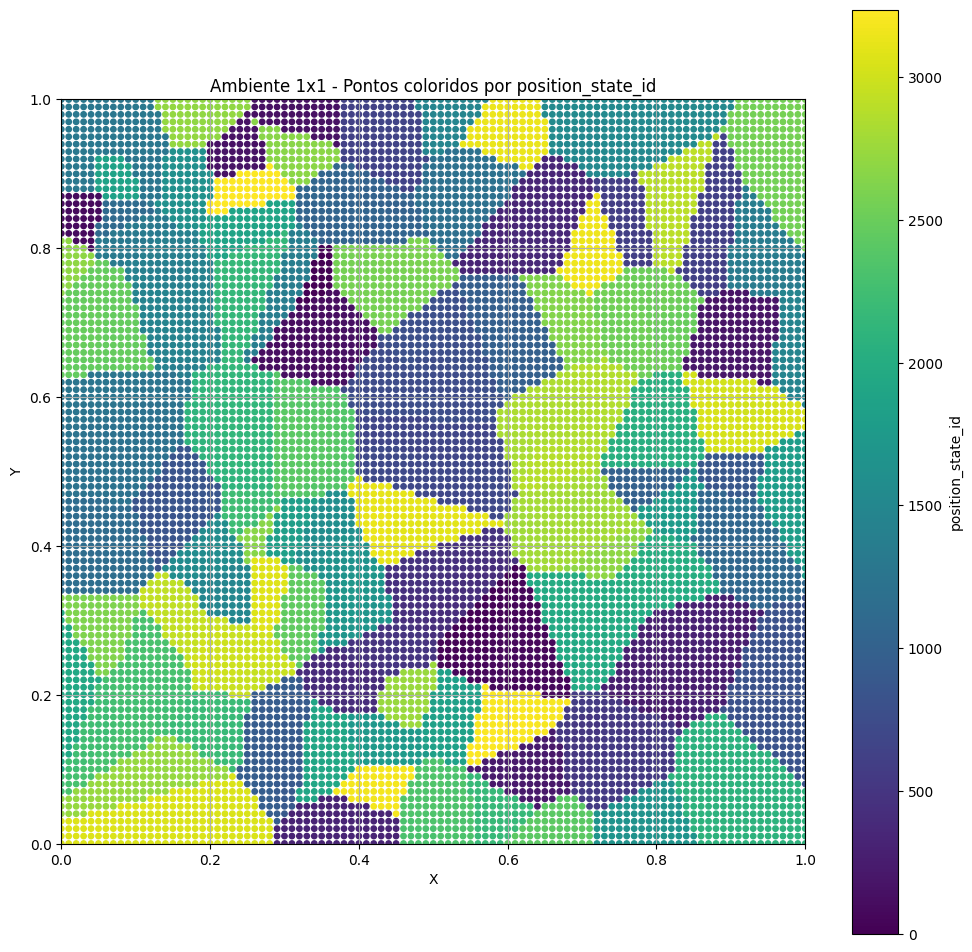

In [ ]:
plt.figure(figsize=(12, 12))
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['position_state_id'], cmap='viridis', s=15)
# Adiciona barra de cores
cbar = plt.colorbar(scatter)
cbar.set_label('position_state_id')

# Configurações visuais
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Região de position states')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')  # ambiente 1x1

plt.show()

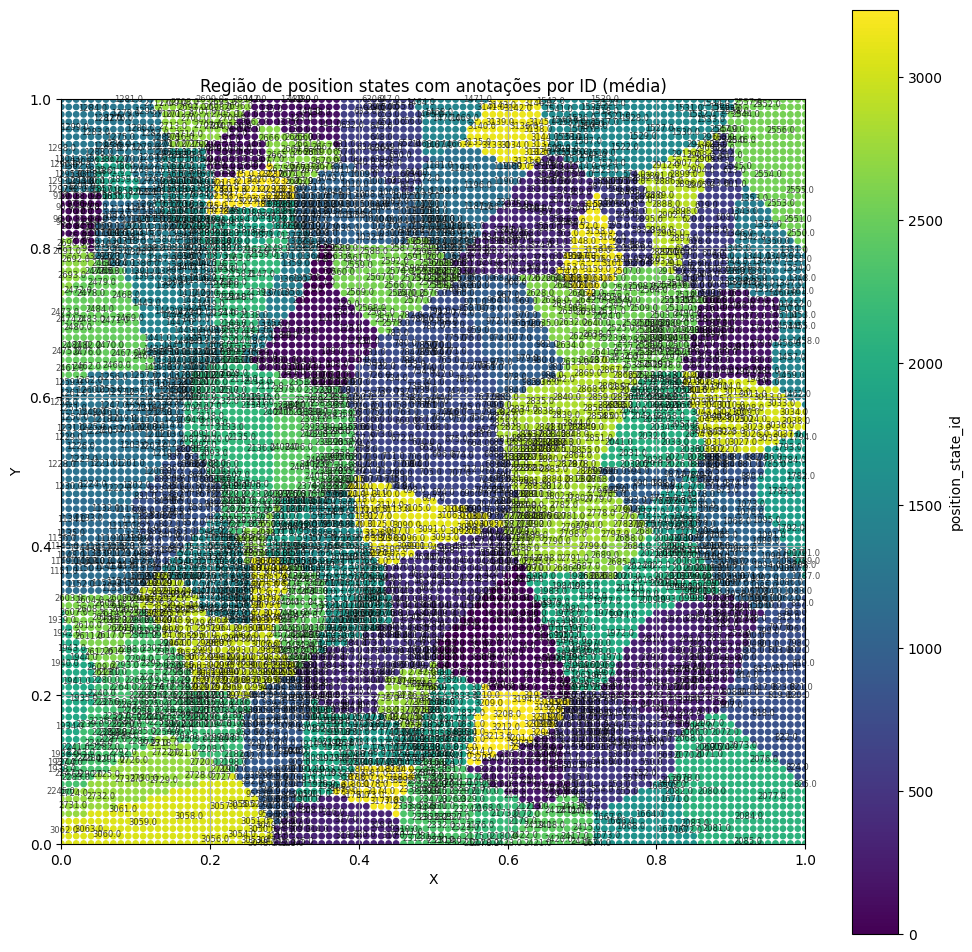

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 12))

# Scatter plot com cor por position_state_id
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['position_state_id'], cmap='viridis', s=15)

# Adiciona barra de cores
cbar = plt.colorbar(scatter)
cbar.set_label('position_state_id')

# Agrupa por position_state_id e calcula média de X e Y
group_means = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()

# Anota cada ponto médio com o ID
for _, row in group_means.iterrows():
    plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                 fontsize=6, alpha=0.7, ha='center', va='center')

# Configurações visuais
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Região de position states com anotações por ID (média)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')

plt.show()


In [72]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()


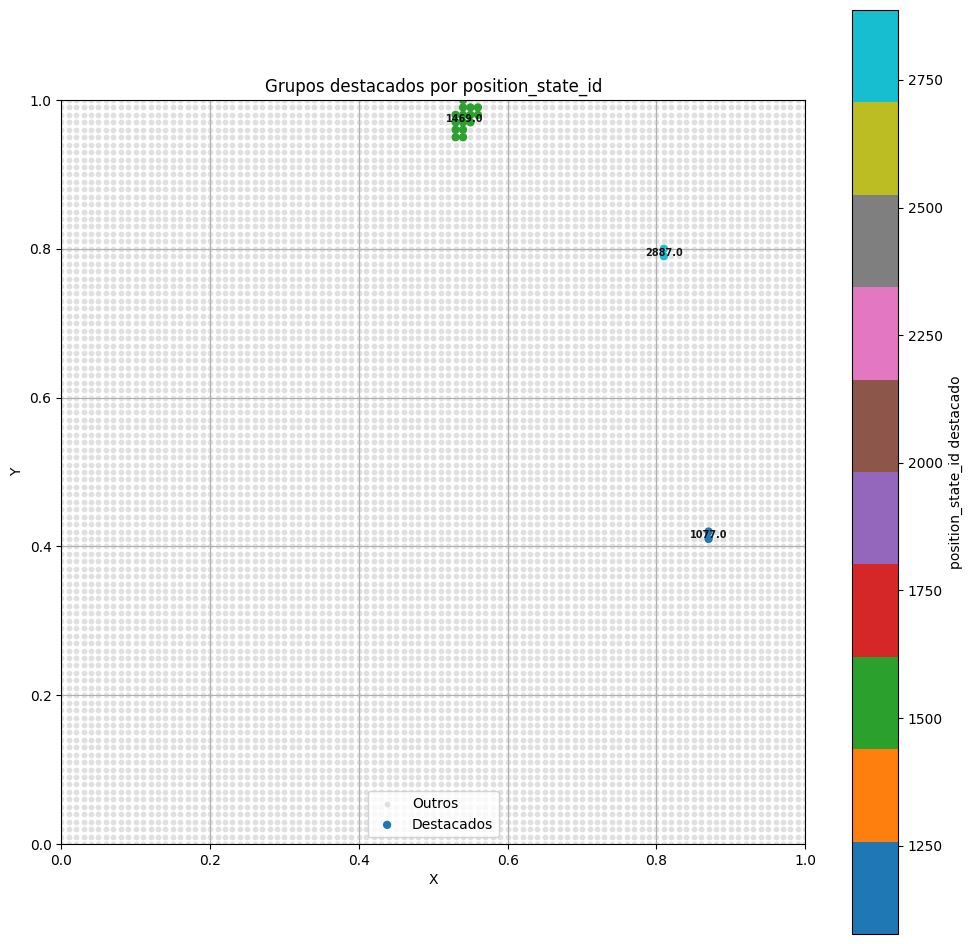

In [73]:
grupos_para_destacar = [2887, 1469, 1077]
plot_position_states(apd, grupos_para_destacar)


In [94]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def plot_position_states_imshow(apd, resolucao=100):
    """
    Plota o mapa completo de position_state_id usando imshow.
    Cada grupo é pintado com uma cor única.
    Um rótulo com o ID é anotado na posição média de cada grupo.

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas discretas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)  # inverte Y para alinhar com o eixo da imagem

    # Inicializa grade com valor inválido (-1)
    mapa = np.full((resolucao, resolucao), -1, dtype=int)

    # Preenche a grade com os position_state_id
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y = linha, x = coluna

    # IDs únicos válidos (exclui -1)
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Mapear IDs para índices de cor
    id_to_idx = {pid: idx for idx, pid in enumerate(unique_ids)}
    color_mapa = np.zeros_like(mapa)
    for pid, idx in id_to_idx.items():
        color_mapa[mapa == pid] = idx

    # Cria colormap discreto
    cmap = plt.cm.get_cmap('tab20', len(unique_ids))
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, len(unique_ids) + 0.5), ncolors=cmap.N)

    # Plot da imagem
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper', extent=[0, 1, 0, 1], interpolation='none')

    # Anotar ponto médio de cada grupo
    medias = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
    # for _, row in medias.iterrows():
    #     plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
    #                  fontsize=7, color='black', ha='center', va='center', fontweight='bold', alpha=0.8)

    # Layout
    plt.title("Mapa completo de position_state_id com anotações")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [98]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_imshow_graph(apd, resolucao=100):
    """
    Plota o mapa completo de position_state_id usando imshow com coloração inteligente:
    grupos vizinhos recebem cores diferentes.

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas discretas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade com valor inválido (-1)
    mapa = np.full((resolucao, resolucao), -1, dtype=int)

    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y = linha, x = coluna

    # IDs únicos válidos (exclui -1)
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # --- Construção do grafo de vizinhança ---
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # --- Colorização do grafo ---
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1

    # Mapeia position_state_id para índices de cor
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Preenche o mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        idx = pid_to_color_idx[pid]
        color_mapa[mapa == pid] = idx

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Layout
    plt.title("Mapa com coloração inteligente (grupos vizinhos com cores distintas)")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [96]:
# grupos_para_destacar = [2887, 1469, 1077]
# plot_position_states_imshow(apd,grupos_para_destacar)


/tmp/ipykernel_15729/1607293999.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', len(unique_ids))


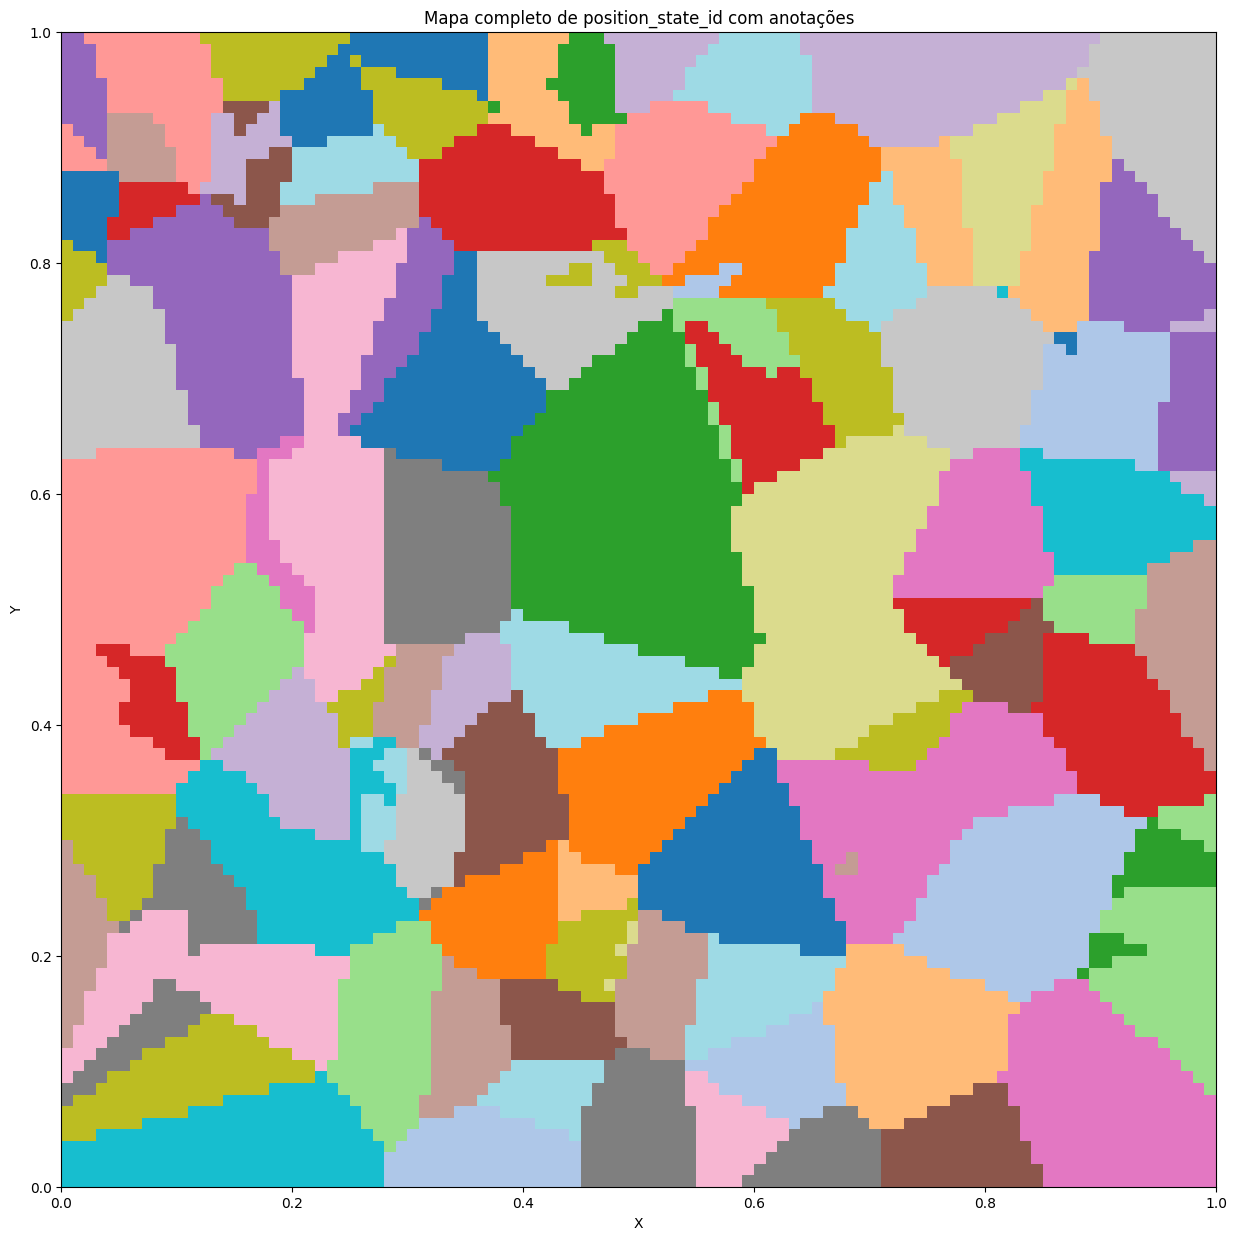

In [97]:
plot_position_states_imshow(apd)

/tmp/ipykernel_15729/1441942947.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


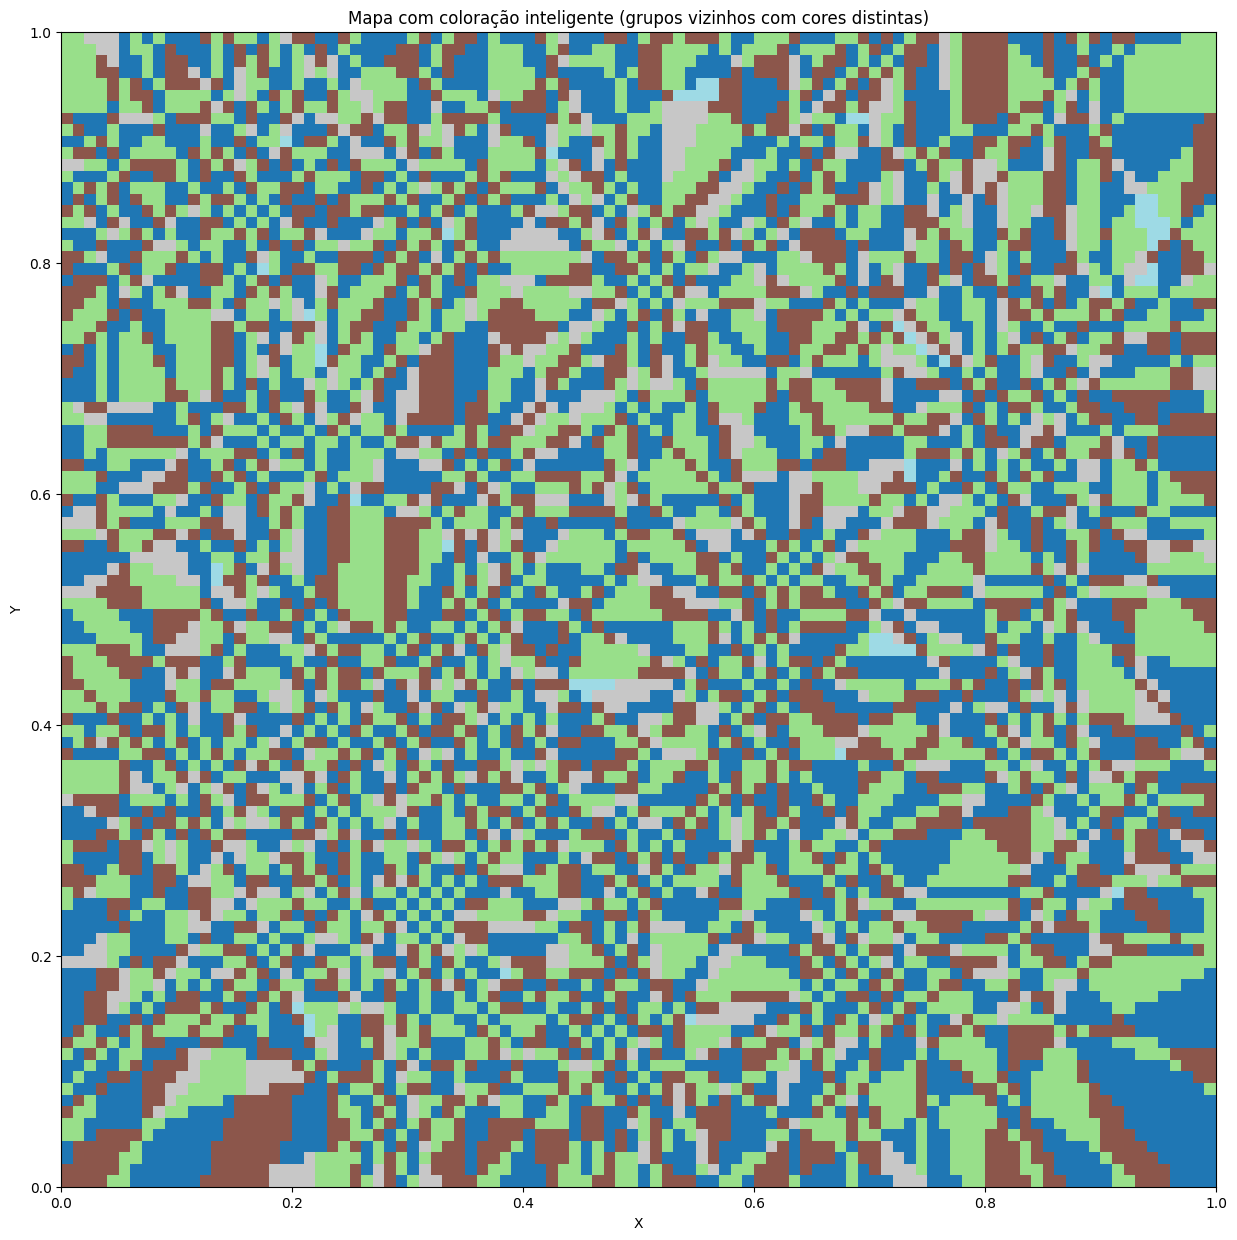

In [102]:
plot_position_states_imshow_graph(apd,)

In [105]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_with_objects(apd, Env, resolucao=100):
    """
    Plota o mapa de position_state_id com coloração inteligente para vizinhos
    e insere pontos de objetos sobrepostos via scatter (em preto).

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - Env: objeto com atributo Env.objects['objects'] (array Nx2 de coordenadas em [0,1])
    - resolucao: resolução da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade
    mapa = np.full((resolucao, resolucao), -1, dtype=int)
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid

    # IDs válidos
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Grafo de vizinhança
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # Colorir com greedy coloring
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Construir mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        color_mapa[mapa == pid] = pid_to_color_idx[pid]

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Scatter de objetos
    objetos = Env.objects['objects']
    plt.scatter(objetos[:, 0], objetos[:, 1], color='black', s=40, label='Objetos')

    # Layout
    plt.title("Mapa de position_state_id com objetos sobrepostos")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.legend()
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


/tmp/ipykernel_15729/281748945.py:54: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


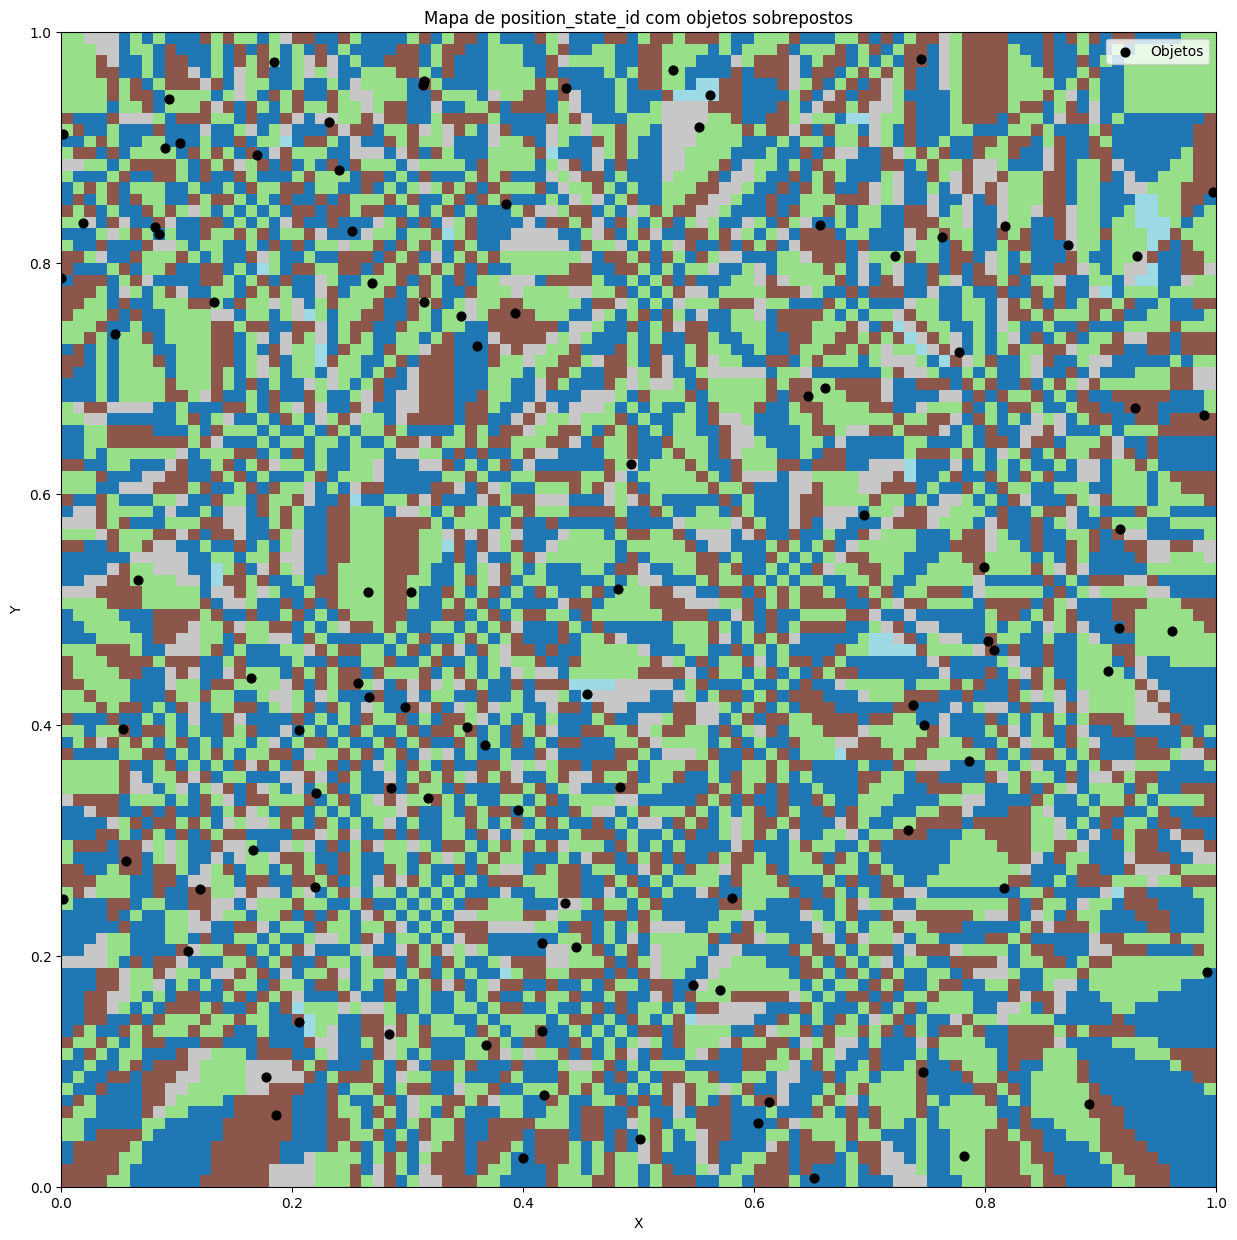

In [106]:
plot_position_states_with_objects(apd, Env)

In [107]:
apd.head()

,X,Y,is_valid,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,...,dist_to_obj_95,dist_to_obj_96,dist_to_obj_97,dist_to_obj_98,dist_to_obj_99,position_state,encode_position_state,position_state_id,normalized_position_state_id,id_index
0,0.00,0.0,1,"[0.0, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.847443,0.447970,0.623911,0.909765,0.855938,WYHEUXUBQOSHORLHQJIQ,"[[0.34659185925924296, 0.6495233614663888, 0.4...",3062,0.633561,0
1,0.01,0.0,1,"[0.01, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.838638,0.441659,0.616655,0.908693,0.846411,WYHEUXUBQOSHQJIQORLH,"[[0.34659185925924296, 0.6495233614663888, 0.4...",3063,0.633768,1
2,0.02,0.0,1,"[0.02, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.829860,0.435487,0.609477,0.907731,0.836895,WYHEUXUBQOSHQJIQORLH,"[[0.34659185925924296, 0.6495233614663888, 0.4...",3063,0.633768,1
3,0.03,0.0,1,"[0.03, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.821110,0.429458,0.602379,0.906878,0.827391,WYHEUXUBQOSHQJIQORLH,"[[0.34659185925924296, 0.6495233614663888, 0.4...",3063,0.633768,1
4,0.04,0.0,1,"[0.04, 0.0]","[0.4833347342209572, 0.3462317422467016]",CRTK,"[0.6465135712032417, 0.6843316975396493]",GUMW,"[0.0014187042901779856, 0.24881128335031188]",ORLH,...,0.812389,0.423580,0.595364,0.906135,0.817898,WYHEUXUBQOSHQJIQORLH,"[[0.34659185925924296, 0.6495233614663888, 0.4...",3063,0.633768,1


In [ ]:
objnum_to_objname = {k:v for k,v in zip(Env.objects['object_names']

['CRTK',
 'GUMW',
 'ORLH',
 'HOTL',
 'WVSP',
 'RCMU',
 'WFHI',
 'UXUB',
 'JNZF',
 'KJOA',
 'JMTF',
 'LOXE',
 'SBCG',
 'MFYH',
 'BQKE',
 'QZFW',
 'GGDR',
 'SLLN',
 'AWYV',
 'BANK',
 'RHMM',
 'HGIV',
 'RVQN',
 'OMLX',
 'CYCR',
 'CKBQ',
 'CUGC',
 'KKYP',
 'RNJI',
 'QEXS',
 'MOFU',
 'BAZN',
 'QUYH',
 'CFWQ',
 'HUHH',
 'QJIQ',
 'DICN',
 'RSZB',
 'IJFH',
 'QICF',
 'NCQL',
 'HUXK',
 'JBQU',
 'HFTJ',
 'IUUK',
 'WFMV',
 'OIQT',
 'JQUV',
 'FXYR',
 'VJGN',
 'HVYG',
 'AUMJ',
 'NJXJ',
 'AEZG',
 'ZQCO',
 'JFBN',
 'STIJ',
 'THGE',
 'QOSH',
 'DVAI',
 'OEHZ',
 'AQQN',
 'LXMN',
 'BKRG',
 'KXXL',
 'XVAV',
 'COVU',
 'YSUL',
 'OWSX',
 'OUJC',
 'VOLD',
 'ZLBA',
 'RCQV',
 'ESOW',
 'KWIY',
 'RWBY',
 'LGNA',
 'PUFL',
 'DDUZ',
 'UJBU',
 'WFTT',
 'POTS',
 'QMSL',
 'KQDO',
 'FTTR',
 'PZIR',
 'FMOW',
 'IFZL',
 'WJEC',
 'FPVJ',
 'UGBA',
 'OMMG',
 'HOCC',
 'WYHE',
 'XWOF',
 'TMBP',
 'XBAC',
 'XDTT',
 'IEHS',
 'BWKU']

In [ ]:
# apd.to_csv(notebook_csv_path('datasets', r'apd.csv'), index=False)

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from skimage.segmentation import find_boundaries
import networkx as nx

def plot_segmented_position_states(apd, resolucao=100):
    """
    Plota um mapa de position_state_id usando imshow com:
    - cores distintas para grupos vizinhos (coloração de grafo)
    - bordas segmentadas entre grupos
    - anotação do ID no ponto médio

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (ex: 100 => 100x100)
    """

    # Conversão para grade discreta
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Grade de IDs
    mapa = np.full((resolucao, resolucao), fill_value=-1, dtype=int)
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y linha, x coluna

    # Coletar IDs únicos
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]
    id_to_index = {pid: idx for idx, pid in enumerate(unique_ids)}

    # --- Construção do grafo de vizinhança ---
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if mapa[ni, nj] != -1 and mapa[ni, nj] != pid:
                    G.add_edge(pid, mapa[ni, nj])

    # --- Colorização do grafo (minimizando repetição de cor entre vizinhos) ---
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1

    # Mapear cores para os grupos
    cmap = plt.cm.get_cmap('tab20', max_color)
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Criar imagem final com índices de cor
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        color_idx = pid_to_color_idx[pid]
        color_mapa[mapa == pid] = color_idx

    # --- Detectar bordas ---
    bordas = find_boundaries(mapa, mode='outer')

    # --- Plot ---
    plt.figure(figsize=(20, 20))
    plt.imshow(color_mapa, cmap=cmap, origin='upper', extent=[0, 1, 0, 1])
    plt.imshow(bordas, cmap='Greys', alpha=0.6, extent=[0, 1, 0, 1])  # sobreposição com bordas

    # Anotar IDs no centro de massa dos grupos
    medias = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
    for _, row in medias.iterrows():
        plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                     fontsize=6.5, color='black', ha='center', va='center', fontweight='bold', alpha=0.8)

    plt.title("Mapa segmentado de position_state_id")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


/tmp/ipykernel_15729/2062470152.py:51: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


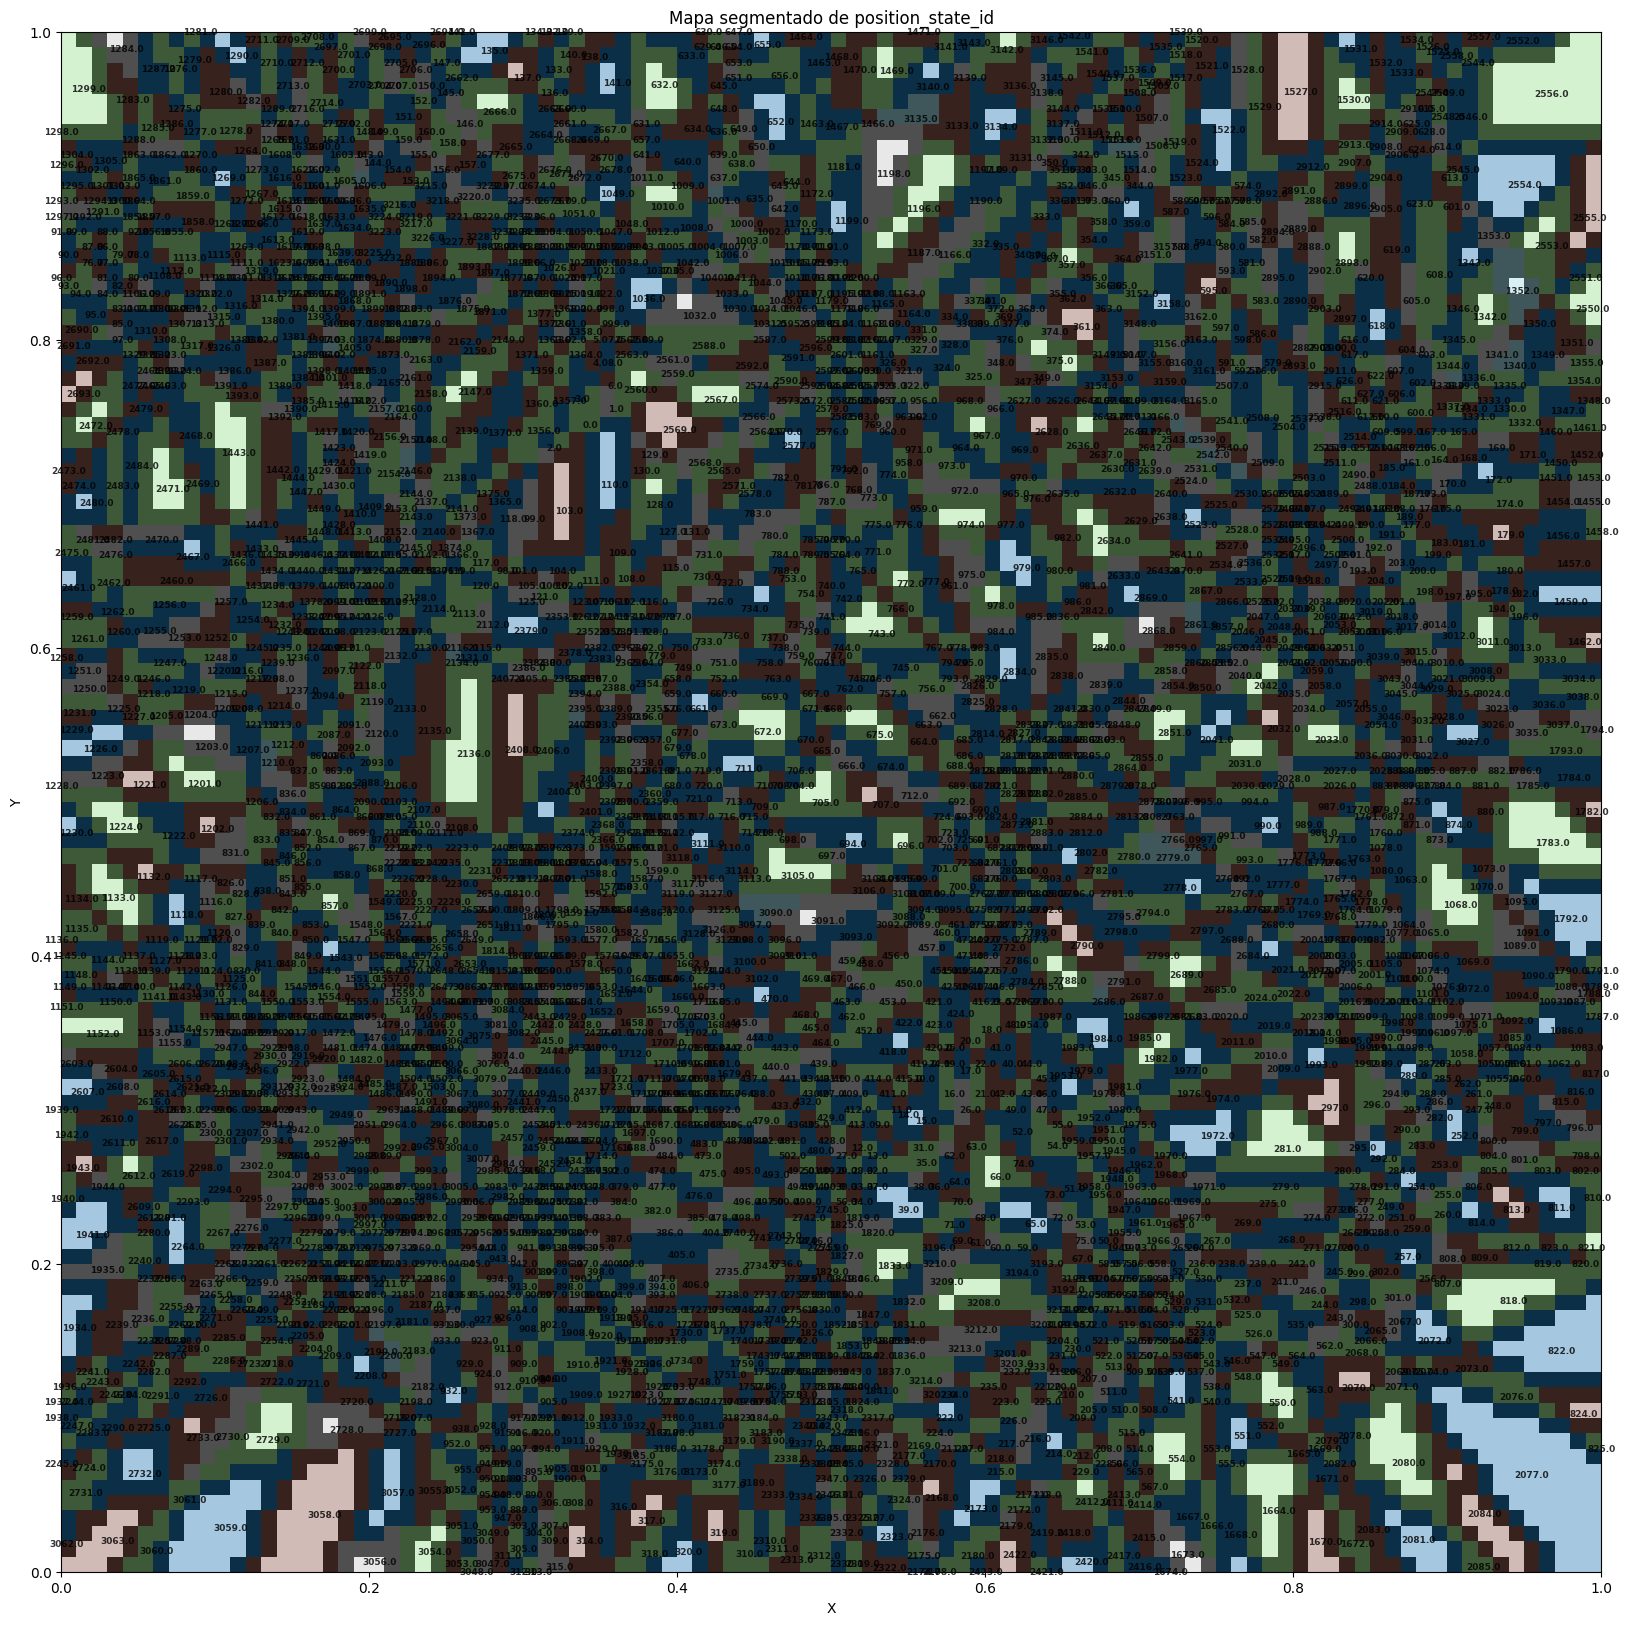

In [89]:
plot_segmented_position_states(apd)

Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 3238 ticks ([0, ..., 3237]), which exceeds Locator.MAXTICKS (1000).
Locator at

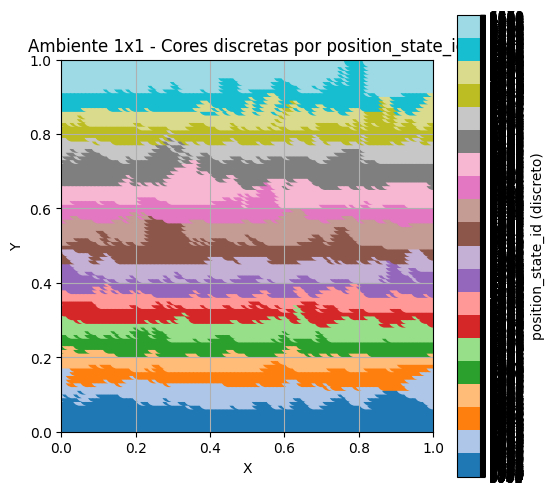

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import ListedColormap, BoundaryNorm


# Mapear cada ID para um índice numérico
unique_ids = apd['position_state_id'].unique()
id_to_index = {id_: idx for idx, id_ in enumerate(unique_ids)}
apd['id_index'] = apd['position_state_id'].map(id_to_index)

# Criar colormap discreto
num_colors = len(unique_ids)
cmap = plt.get_cmap('tab20', num_colors)  # você pode trocar 'tab20' por outras como 'Set3', 'Accent', etc.
norm = BoundaryNorm(np.arange(-0.5, num_colors + 0.5, 1), cmap.N)

# Plot
plt.figure(figsize=(6, 6))
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['id_index'], cmap=cmap, norm=norm, s=100)

# Barra de cores com rótulos personalizados
cbar = plt.colorbar(scatter, ticks=range(num_colors))
cbar.ax.set_yticklabels([str(id_) for id_ in unique_ids])
cbar.set_label('position_state_id (discreto)')

# Configurações do gráfico
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Ambiente 1x1 - Cores discretas por position_state_id')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')

plt.show()


In [166]:
dfp.shape

(36000, 70)

In [167]:
dfp[['position_state', 'position_state_id', 'normalized_position_state_id', 'encode_position_state']].iloc[8:12]

,position_state,position_state_id,normalized_position_state_id,encode_position_state
8,CTYTRCRZKVYTLGNIIWLC,62,0.132196,"[[0.20793834753393803, 0.32408491525119565, 0...."
9,CTYTRCRZKVYTLGNIIWLC,62,0.132196,"[[0.20793834753393803, 0.32408491525119565, 0...."
10,RCRZCTYTKVYTLGNIIWLC,260,0.554371,"[[0.32408491525119565, 0.20793834753393803, 0...."
11,RCRZCTYTKVYTLGNIIWLC,260,0.554371,"[[0.32408491525119565, 0.20793834753393803, 0...."


In [168]:
# help(Ag.plot_trajectory)

## get change of pos

In [169]:
dfp['last_position_state_id'] = (dfp['position_state_id'].shift(1))
dfp.shape

(36000, 71)

<Axes: >

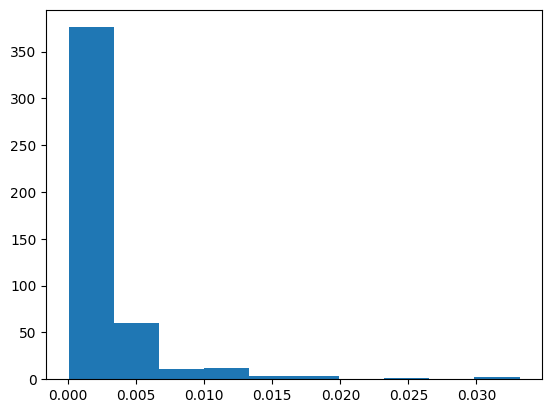

In [193]:
dfp['position_state_id'].value_counts(normalize=True,).hist(grid=False)

In [170]:
dfp[['position_state', 'position_state_id', 'last_position_state_id', 'encode_position_state']].iloc[8:12]

,position_state,position_state_id,last_position_state_id,encode_position_state
8,CTYTRCRZKVYTLGNIIWLC,62,62.0,"[[0.20793834753393803, 0.32408491525119565, 0...."
9,CTYTRCRZKVYTLGNIIWLC,62,62.0,"[[0.20793834753393803, 0.32408491525119565, 0...."
10,RCRZCTYTKVYTLGNIIWLC,260,62.0,"[[0.32408491525119565, 0.20793834753393803, 0...."
11,RCRZCTYTKVYTLGNIIWLC,260,260.0,"[[0.32408491525119565, 0.20793834753393803, 0...."


In [171]:
dfp[['position_state_id', 'last_position_state_id']].dtypes

position_state_id           int64
last_position_state_id    float64
dtype: object

In [172]:
dfp.shape

(36000, 71)

In [173]:
len(dfp['position_state_id'])

36000

In [174]:
change_dict_ = {'change_of_position_state':[int(pos!=last_pos) for pos, last_pos in zip(dfp['position_state_id'].astype('float'), dfp['last_position_state_id'])]}
change_dict_df = pd.DataFrame(change_dict_)

print(change_dict_df.shape)
# dfp = pd.concat([dfp, change_dict_df], ignore_index=True, axis=0)

(36000, 1)


In [175]:
dfp.shape

(36000, 71)

In [176]:
dfp['change_of_position_state'] = (change_dict_df['change_of_position_state'])

In [177]:
dfp.shape

(36000, 72)

In [178]:
# dfp['change_of_position_state'].values

In [179]:
dfp[['position_state', 'position_state_id', 'last_position_state_id', 'change_of_position_state']].iloc[8:12]

,position_state,position_state_id,last_position_state_id,change_of_position_state
8,CTYTRCRZKVYTLGNIIWLC,62,62.0,0
9,CTYTRCRZKVYTLGNIIWLC,62,62.0,0
10,RCRZCTYTKVYTLGNIIWLC,260,62.0,1
11,RCRZCTYTKVYTLGNIIWLC,260,260.0,0


In [180]:
dfp[dfp['change_of_position_state'] == 1][['position_state_id', 'last_position_state_id', 'change_of_position_state']].head()

,position_state_id,last_position_state_id,change_of_position_state
0,63,NaN,1
4,62,63.0,1
10,260,62.0,1
25,256,260.0,1
32,255,256.0,1


In [181]:
dfp[dfp['change_of_position_state'] == 1].shape

(4607, 72)

In [182]:
dfp['change_of_position_state'].mean()

0.1279722222222222

# train df

In [183]:
dfc = dfp[dfp['change_of_position_state'] == 1].iloc[1:].reset_index(drop=True).copy()
dfc.shape

(4606, 72)

In [184]:
dfc['encode_position_state'].shape

(4606,)

In [185]:
dfc['encode_position_state'].values[0]

array([[0.20793835, 0.32408492, 0.3349807 , 0.68008423, 0.39028159],
       [0.06080899, 0.11342241, 0.42642896, 0.41264501, 0.87962507],
       [0.56883003, 0.6301949 , 0.22733239, 0.66490596, 0.93015934]])

In [186]:
dfc['encode_position_state'].values[0].shape

(3, 5)

<Axes: >

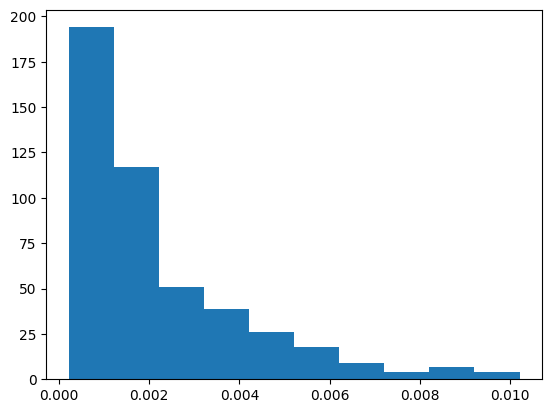

In [195]:
dfc['position_state_id'].value_counts(normalize=True).hist(grid=False)

In [187]:
# help(plt.imshow)

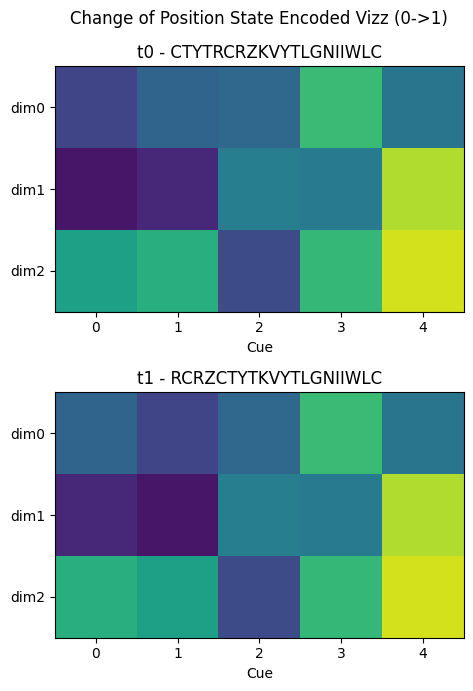

In [188]:
fig, ax = plt.subplots(2, 1, figsize=(16, 7))

t0 = 0
t1 = 1

plt.suptitle(f'Change of Position State Encoded Vizz ({t0}->{t1})')
p1 = ax[0].imshow(dfc['encode_position_state'].values[t0],vmin=0, vmax=1)
# plt.colorbar(p1, ax=ax[1])
p2 = ax[1].imshow(dfc['encode_position_state'].values[t1],vmin=0, vmax=1)
# plt.colorbar(p2, ax=ax[1])
ax[0].set_title(f't{t0} - {dfc["position_state"].values[t0]}',)
ax[1].set_title(f't{t1} - {dfc["position_state"].values[t1]}',)


ax[0].set_yticks([0, 1, 2])
ax[0].set_yticklabels(['dim0', 'dim1', 'dim2'])
ax[0].set_xlabel('Cue')

ax[1].set_yticks([0, 1, 2])
ax[1].set_yticklabels(['dim0', 'dim1', 'dim2'])
ax[1].set_xlabel('Cue')
# ax[0].set_()
plt.tight_layout()
plt.show()

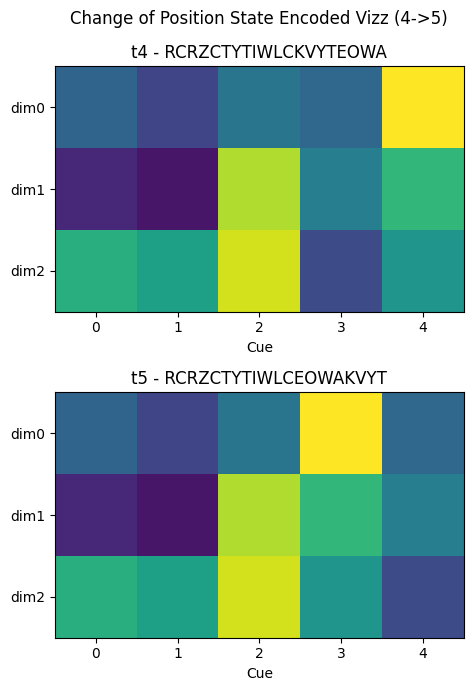

In [189]:
fig, ax = plt.subplots(2, 1, figsize=(16, 7))

t0 = 4
t1 = 5

plt.suptitle(f'Change of Position State Encoded Vizz ({t0}->{t1})')
p1 = ax[0].imshow(dfc['encode_position_state'].values[t0],vmin=0, vmax=1)
# plt.colorbar(p1, ax=ax[1])
p2 = ax[1].imshow(dfc['encode_position_state'].values[t1],vmin=0, vmax=1)
# plt.colorbar(p2, ax=ax[1])
ax[0].set_title(f't{t0} - {dfc["position_state"].values[t0]}',)
ax[1].set_title(f't{t1} - {dfc["position_state"].values[t1]}',)


ax[0].set_yticks([0, 1, 2])
ax[0].set_yticklabels(['dim0', 'dim1', 'dim2'])
ax[0].set_xlabel('Cue')

ax[1].set_yticks([0, 1, 2])
ax[1].set_yticklabels(['dim0', 'dim1', 'dim2'])
ax[1].set_xlabel('Cue')
# ax[0].set_()
plt.tight_layout()
plt.show()

In [190]:
dfc.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_0_enc,obj_1_pos,...,dist_to_obj_11,dist_to_obj_12,dist_to_obj_13,dist_to_obj_14,position_state,encode_position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.25,"[0.6820112650872491, 0.4728664244776024]",0.027811,"[-0.01566934209907833, -0.06868062391330976]",0.026323,"[-0.4258184861370507, -0.9048086078635362]","[0.38798593827367855, 0.9805671096022476]",RUIZ,"[[0.15184775543595386], [0.7833317405988385], ...","[0.26280893128411154, 0.1910002672169574]",...,0.322751,0.473441,0.646989,0.403790,CTYTRCRZKVYTLGNIIWLC,"[[0.20793834753393803, 0.32408491525119565, 0....",62,0.132196,63.0,1
1,0.55,"[0.663985472742647, 0.4591009778508717]",0.051235,"[-0.09298784207982802, -0.030763312846688873]",-4.067070,"[-0.8391207421663309, -0.5439451995065551]","[0.38798593827367855, 0.9805671096022476]",RUIZ,"[[0.15184775543595386], [0.7833317405988385], ...","[0.26280893128411154, 0.1910002672169574]",...,0.317794,0.487173,0.624309,0.419558,RCRZCTYTKVYTLGNIIWLC,"[[0.32408491525119565, 0.20793834753393803, 0....",260,0.554371,62.0,1


In [191]:
dfc.columns

Index(['t', 'pos', 'distance_travelled', 'vel', 'rot_vel', 'head_direction',
       'obj_0_pos', 'obj_0_name', 'obj_0_enc', 'obj_1_pos', 'obj_1_name',
       'obj_1_enc', 'obj_2_pos', 'obj_2_name', 'obj_2_enc', 'obj_3_pos',
       'obj_3_name', 'obj_3_enc', 'obj_4_pos', 'obj_4_name', 'obj_4_enc',
       'obj_5_pos', 'obj_5_name', 'obj_5_enc', 'obj_6_pos', 'obj_6_name',
       'obj_6_enc', 'obj_7_pos', 'obj_7_name', 'obj_7_enc', 'obj_8_pos',
       'obj_8_name', 'obj_8_enc', 'obj_9_pos', 'obj_9_name', 'obj_9_enc',
       'obj_10_pos', 'obj_10_name', 'obj_10_enc', 'obj_11_pos', 'obj_11_name',
       'obj_11_enc', 'obj_12_pos', 'obj_12_name', 'obj_12_enc', 'obj_13_pos',
       'obj_13_name', 'obj_13_enc', 'obj_14_pos', 'obj_14_name', 'obj_14_enc',
       'dist_to_obj_0', 'dist_to_obj_1', 'dist_to_obj_2', 'dist_to_obj_3',
       'dist_to_obj_4', 'dist_to_obj_5', 'dist_to_obj_6', 'dist_to_obj_7',
       'dist_to_obj_8', 'dist_to_obj_9', 'dist_to_obj_10', 'dist_to_obj_11',
       'dist_to_ob

In [196]:
columns_to_keep = [
    't',
    'pos',
    'distance_travelled',
    'vel',
    'rot_vel',
    'head_direction',
    'position_state',
    'encode_position_state',
    'position_state_id',
    'normalized_position_state_id',
    'last_position_state_id',
    'change_of_position_state',
]

In [197]:
print(dfc[columns_to_keep].shape)
dfc[columns_to_keep].to_csv(notebook_csv_path('datasets', 'df_trainset_v3.csv'), index=False)

(4606, 12)


In [92]:
dfc[columns_to_keep].head(5)

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,encode_position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.1,"[0.0278055786059123, 0.1811448452632181]",0.007195,"[-0.016308665919082047, -0.05830984791019789]",1.403580,"[-0.2927907807652273, -0.9561765311378901]",LYQUARHRBGKPVGSAYVAJ,"[[0.3773149262903418, 0.5994557324261423, 0.84...",914,0.443259,913.0,1
1,1.0,"[0.008635554764255324, 0.09477351416502597]",0.103615,"[0.05304462245872566, -0.08846917237401913]",4.290806,"[0.13129593872626943, -0.9913432183023132]",LYQUVGSABGKPARHRYVAJ,"[[0.3773149262903418, 0.9881177956943856, 0.84...",921,0.446654,914.0,1
2,1.3,"[0.021185587000414143, 0.0687409175200043]",0.132656,"[0.056635850656752695, -0.08031650624382186]",0.993481,"[0.4652929332814854, -0.8851567580029602]",LYQUVGSABGKPYVAJARHR,"[[0.3773149262903418, 0.9881177956943856, 0.84...",922,0.447139,921.0,1
3,3.5,"[0.10999436731587446, 0.10190571724610982]",0.252188,"[0.02355639871516796, 0.0732388474430215]",1.175689,"[0.3652701660735007, 0.9309015553626694]",LYQUBGKPVGSAYVAJARHR,"[[0.3773149262903418, 0.8401833272681568, 0.98...",919,0.445684,922.0,1
4,5.0,"[0.15649559190109852, 0.19619477886184228]",0.361036,"[0.03911471293203517, 0.09470768523600459]",5.168793,"[0.5964649365874699, 0.8026391339959107]",BGKPLYQUVGSAARHRYVAJ,"[[0.8401833272681568, 0.3773149262903418, 0.98...",164,0.079534,919.0,1


In [93]:
dfc['position_state'].values[:3]

array(['LYQUARHRBGKPVGSAYVAJ', 'LYQUVGSABGKPARHRYVAJ',
       'LYQUVGSABGKPYVAJARHR'], dtype=object)

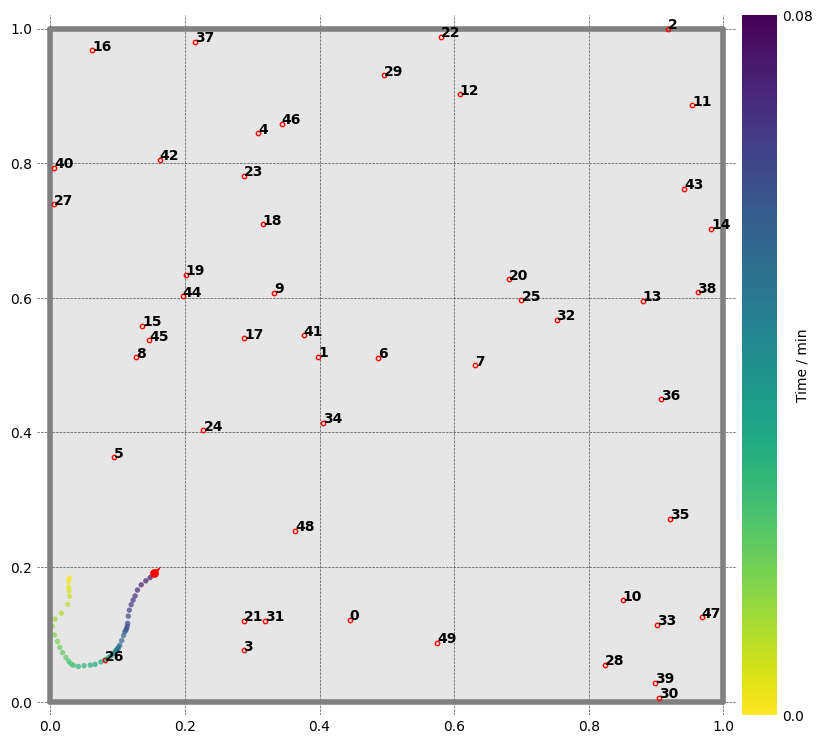

In [95]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=dfc['t'].values[5])

plt.show()

# FIM

## explode xpos and ypos

In [57]:
df['x_pos'] = (df['pos'].explode()[::2])
df['y_pos'] = (df['pos'].explode()[1::2])

In [55]:
df['y_pos'].max()

0.9999915713572776

In [56]:
# df['pos'].explode()[::2]

In [57]:
# df.to_csv(notebook_csv_path('datasets', 'results_100_objs.csv'), index=False)

In [58]:
FIXED_OBJECT = 10

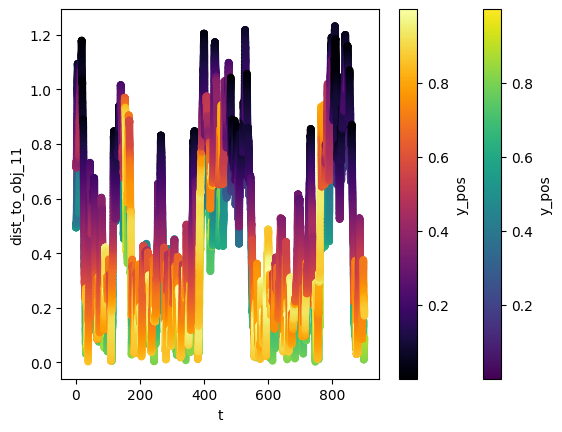

In [59]:
fig, ax = plt.subplots()
df.plot.scatter(x='t', y=f'dist_to_obj_{FIXED_OBJECT}', c='y_pos',ax=ax)
df.plot.scatter(x='t', y=f'dist_to_obj_{FIXED_OBJECT+1}', c='y_pos',ax=ax, cmap='inferno')
plt.show()

In [60]:

# df['last_position_state'] = df['position_state'].shift(1)

In [61]:
# df['change_of_state'] = int(df['position_state'].str == df['last_position_state'].str)

In [62]:
# df['change_of_state'].mean()

In [63]:
pd.set_option('display.max_colwidth', None)
df[['t', 'position_state', 'x_pos', 'y_pos']].iloc[50:55]

,t,position_state,x_pos,y_pos
50,2.55,ICTBNEQOIRZATWTOGPCQOGAKGRZQ,0.388353,0.353485
51,2.60,ICTBIRZANEQOTWTOGPCQOGAKGRZQ,0.387351,0.346321
52,2.65,IRZATWTONEQOICTBGPCQOGAKGRZQ,0.386919,0.341018
53,2.70,IRZATWTONEQOICTBGPCQOGAKGRZQ,0.385951,0.337239
54,2.75,IRZATWTONEQOICTBGPCQOGAKGRZQ,0.383549,0.331795
